# FOM Dataset Generation for Navier–Stokes POD/PODNN

This notebook reuses the finite-element/full-order-model setup from the POD-Galerkin implementation.

Its only job is to generate and permanently save full-order snapshots

\[
(\mu_0,\mu_1) \longrightarrow U_{\mathrm{FOM}}(\mu_0,\mu_1).
\]

The saved dataset will later be used by both the POD-Galerkin and PODNN workflows.
No POD construction and no neural-network training are done here.


In [30]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ColabNotebooks/MOR-Project"
%cd $PROJECT_DIR

!pip install -r requirements.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/ColabNotebooks/MOR-Project


In [31]:
import numpy as np
import argparse
import os.path
import scipy.sparse
import vtk
import time
from pypolydim import polydim, gedim
from pypolydim.export_vtk_utilities import ExportVTKUtilities
from pypolydim.assembler_utilities import assembler_utilities

import sys
sys.path.insert(1, '../')
import other_utilities as other_ut

## 1. FEM model setup

The next cells are copied from the working POD-Galerkin notebook. They define the domain,
mesh, finite-element spaces, operators, forcing, and boundary-value objects needed by the FOM solver.


In [32]:
geometry_utilities_config = gedim.GeometryUtilitiesConfig()

geometry_utilities_config.tolerance1_d = 1.0e-6
geometry_utilities_config.tolerance2_d = 1.0e-12

geometry_utilities = gedim.GeometryUtilities(
    geometry_utilities_config
)

mesh_utilities = gedim.MeshUtilities()

vtk_utilities = ExportVTKUtilities()

In [33]:
pde_domain = polydim.pde_tools.mesh.pde_mesh_utilities.PDE_Domain_2D()

pde_domain.vertices = np.array([
    [0.0, 1.0, 1.0, 0.0],
    [0.0, 0.0, 1.0, 1.0],
    [0.0, 0.0, 0.0, 0.0]
])

pde_domain.shape_type = (
    polydim.pde_tools.mesh.pde_mesh_utilities
    .PDE_Domain_2D.Domain_Shape_Types.parallelogram
)

pde_domain.area = 1.0

In [34]:
mesh_type = (
    polydim.pde_tools.mesh.pde_mesh_utilities
    .MeshGenerator_Types_2D.triangular
)

method_type = (
    polydim.pde_tools.local_space_pcc_2_d.MethodTypes.fem_pcc
)

mesh_size = 0.001

In [35]:
mesh_data = gedim.MeshMatrices()

mesh = gedim.MeshMatricesDAO(mesh_data)

polydim.pde_tools.mesh.pde_mesh_utilities.create_mesh_2_d(
    geometry_utilities,
    mesh_utilities,
    mesh_type,
    pde_domain,
    mesh_size,
    mesh
)

mesh_geometric_data = (
    polydim.pde_tools.mesh.pde_mesh_utilities
    .compute_mesh_2_d_geometry_data(
        geometry_utilities,
        mesh_utilities,
        mesh
    )
)

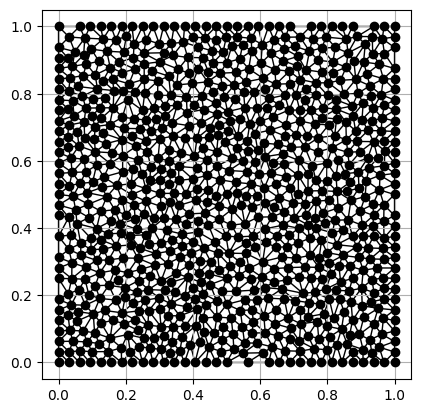

In [36]:
other_ut.plot_mesh(mesh)

In [37]:
# Defining border info.
info_internal = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none)
info_internal.marker = 0

info_dirichlet = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.strong)
info_dirichlet.marker = 1

info_neumann_none = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none)
info_neumann_none.marker = 0

# p=0 on all borders.
pressure_boundary_info = {
    0: info_internal,
    1: info_dirichlet,
    2: info_neumann_none,
    3: info_neumann_none,
    4: info_neumann_none,
    5: info_neumann_none,
    6: info_neumann_none,
    7: info_neumann_none,
    8: info_neumann_none
}

# u=v=0 on all borders.
speed_boundary_info = {
    0: info_internal,
    1: info_dirichlet,
    2: info_dirichlet,
    3: info_dirichlet,
    4: info_dirichlet,
    5: info_dirichlet,
    6: info_dirichlet,
    7: info_dirichlet,
    8: info_dirichlet
}

In [38]:
# ============================================================
# Mesh connectivity and reference elements
# ============================================================

mesh_connectivity_data = (
    polydim.pde_tools.mesh
    .MeshMatricesDAO_mesh_connectivity_data(mesh)
)

pressure_reference_element_data = (
    polydim.pde_tools.local_space_pcc_2_d
    .create_reference_element(method_type, 1)
)

speed_reference_element_data = (
    polydim.pde_tools.local_space_pcc_2_d
    .create_reference_element(method_type, 2)
)

dof_manager = polydim.pde_tools.do_fs.DOFsManager()


# ============================================================
# Pressure DOFs
# ============================================================

pressure_mesh_dofs_info = (
    polydim.pde_tools.local_space_pcc_2_d
    .set_mesh_do_fs_info(
        pressure_reference_element_data,
        mesh,
        pressure_boundary_info
    )
)

pressure_dofs_data = (
    dof_manager.create_do_fs_2_d(
        pressure_mesh_dofs_info,
        mesh_connectivity_data
    )
)


# ============================================================
# Velocity DOFs
# ============================================================

speed_mesh_dofs_info = (
    polydim.pde_tools.local_space_pcc_2_d
    .set_mesh_do_fs_info(
        speed_reference_element_data,
        mesh,
        speed_boundary_info
    )
)

speed_dofs_data = (
    dof_manager.create_do_fs_2_d(
        speed_mesh_dofs_info,
        mesh_connectivity_data
    )
)

In [39]:
pressure_n_dofs = pressure_dofs_data.number_do_fs
pressure_n_strongs = pressure_dofs_data.number_strongs

speed_n_dofs = speed_dofs_data.number_do_fs
speed_n_strongs = speed_dofs_data.number_strongs

tot_dofs = 2 * speed_n_dofs + pressure_n_dofs
tot_strongs = 2 * speed_n_strongs + pressure_n_strongs

print("Pressure DOFs :", pressure_n_dofs)
print("Velocity DOFs :", 2 * speed_n_dofs)
print("Total DOFs    :", tot_dofs)

print("Pressure strong DOFs :", pressure_n_strongs)
print("Velocity strong DOFs :", 2 * speed_n_strongs)
print("Total strong DOFs    :", tot_strongs)

Pressure DOFs : 829
Velocity DOFs : 5932
Total DOFs    : 6761
Pressure strong DOFs : 1
Velocity strong DOFs : 468
Total strong DOFs    : 469


In [40]:
def unit_term(x, y, z):
    return 1.0

def b_x_term(x, y, z):
    return np.array([1.0, 0.0, 0.0])


def b_y_term(x, y, z):
    return np.array([0.0, 1.0, 0.0])

In [41]:
def make_f_functions(mu1):

    pi = np.pi

    def f_x_function(x, y, z):
        return (
            -(mu1**3 * pi**2 * np.cos(mu1**2 * pi * x)
              - mu1**2 * pi**2)
            * np.sin(mu1 * pi * y)
            * np.cos(mu1 * pi * y)
            + mu1 * pi
            * np.cos(mu1 * pi * x)
            * np.cos(mu1 * pi * y)
        )

    def f_y_function(x, y, z):
        return (
            -(-mu1**3 * pi**2 * np.cos(mu1**2 * pi * y)
              + mu1**2 * pi**2)
            * np.sin(mu1 * pi * x)
            * np.cos(mu1 * pi * x)
            - mu1 * pi
            * np.sin(mu1 * pi * x)
            * np.sin(mu1 * pi * y)
        )

    return f_x_function, f_y_function

In [42]:
def assemble_f(mu1):

    f_x_function, f_y_function = make_f_functions(mu1)

    f_x = (
        polydim.pde_tools.assembler_utilities.pcc_2_d
        .assemble_source_term(
            geometry_utilities,
            mesh,
            mesh_geometric_data,
            speed_dofs_data,
            speed_reference_element_data,
            speed_reference_element_data,
            f_x_function
        )
    )

    f_y = (
        polydim.pde_tools.assembler_utilities.pcc_2_d
        .assemble_source_term(
            geometry_utilities,
            mesh,
            mesh_geometric_data,
            speed_dofs_data,
            speed_reference_element_data,
            speed_reference_element_data,
            f_y_function
        )
    )

    return np.concatenate([
        f_x,
        f_y,
        np.zeros(pressure_n_dofs)
    ])

In [43]:
F_test = assemble_f(mu1=2.0)

print("F shape:", F_test.shape)
print("Expected:", (tot_dofs,))
print("||F|| =", np.linalg.norm(F_test))

F shape: (6761,)
Expected: (6761,)
||F|| = 0.7217278387973323


In [44]:
# ============================================================
# SAVE MESH AND DOF INFORMATION FOR PINN / POST-PROCESSING
# ============================================================

# ------------------------------------------------------------
# 1. Mesh vertex coordinates
# ------------------------------------------------------------

DATA_DIR = os.path.join(PROJECT_DIR, "data", "fom")

n_vertices = mesh.cell0_d_total_number()

mesh_coordinates = np.array(
    [
        [
            mesh.cell0_d_coordinate_x(i),
            mesh.cell0_d_coordinate_y(i)
        ]
        for i in range(n_vertices)
    ],
    dtype=np.float32
)


# ------------------------------------------------------------
# 2. Pressure and velocity DOF mapping
# ------------------------------------------------------------

pressure_dof_indices = np.full(
    n_vertices,
    -1,
    dtype=np.int64
)

velocity_dof_indices = np.full(
    n_vertices,
    -1,
    dtype=np.int64
)

pressure_dof_types = np.full(
    n_vertices,
    -1,
    dtype=np.int64
)

for i in range(n_vertices):

    p_dofs = pressure_dofs_data.cells_do_fs[0][i]
    u_dofs = speed_dofs_data.cells_do_fs[0][i]

    if len(p_dofs) > 0:

        pressure_dof_indices[i] = (
            p_dofs[0].global_index
        )

        pressure_dof_types[i] = int(
            p_dofs[0].type
        )

    if len(u_dofs) > 0:

        velocity_dof_indices[i] = (
            u_dofs[0].global_index
        )


# ------------------------------------------------------------
# 3. Global DOF counts
# ------------------------------------------------------------

mesh_info = {
    "n_vertices": n_vertices,
    "speed_n_dofs": speed_n_dofs,
    "pressure_n_dofs": pressure_n_dofs,
    "total_dofs": tot_dofs,
}


# ------------------------------------------------------------
# 4. Save
# ------------------------------------------------------------

np.save(
    os.path.join(
        DATA_DIR,
        "mesh_coordinates.npy"
    ),
    mesh_coordinates
)

np.save(
    os.path.join(
        DATA_DIR,
        "pressure_dof_indices.npy"
    ),
    pressure_dof_indices
)

np.save(
    os.path.join(
        DATA_DIR,
        "velocity_dof_indices.npy"
    ),
    velocity_dof_indices
)

np.save(
    os.path.join(
        DATA_DIR,
        "pressure_dof_types.npy"
    ),
    pressure_dof_types
)

np.save(
    os.path.join(
        DATA_DIR,
        "mesh_info.npy"
    ),
    mesh_info
)

print("Mesh and DOF information saved.")
print("  mesh_coordinates.npy")
print("  pressure_dof_indices.npy")
print("  velocity_dof_indices.npy")
print("  pressure_dof_types.npy")
print("  mesh_info.npy")

Mesh and DOF information saved.
  mesh_coordinates.npy
  pressure_dof_indices.npy
  velocity_dof_indices.npy
  pressure_dof_types.npy
  mesh_info.npy


In [45]:
# ============================================================
# SAVE PINN-READY NODAL DATA
# ============================================================

# Nodes where all three fields can be associated
valid_nodes = (
    (pressure_dof_indices >= 0)
    &
    (velocity_dof_indices >= 0)
)

pinn_coordinates = mesh_coordinates[valid_nodes]

pinn_pressure_indices = (
    pressure_dof_indices[valid_nodes]
)

pinn_velocity_indices = (
    velocity_dof_indices[valid_nodes]
)

np.save(
    os.path.join(
        DATA_DIR,
        "pinn_coordinates.npy"
    ),
    pinn_coordinates
)

np.save(
    os.path.join(
        DATA_DIR,
        "pinn_pressure_indices.npy"
    ),
    pinn_pressure_indices
)

np.save(
    os.path.join(
        DATA_DIR,
        "pinn_velocity_indices.npy"
    ),
    pinn_velocity_indices
)

print()
print("PINN-ready mesh data saved.")
print(
    "PINN nodes:",
    pinn_coordinates.shape[0]
)


PINN-ready mesh data saved.
PINN nodes: 830


In [46]:
# ============================================================
# FEM diffusion operator
# ============================================================

A_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_diffusion_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_dofs_data,
        speed_dofs_data,
        speed_reference_element_data,
        speed_reference_element_data,
        unit_term
    )
)

J_A_x = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [0, 0]
)

J_A_y = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [speed_n_dofs, speed_n_dofs]
)

J_A = J_A_x + J_A_y


# ============================================================
# Velocity-pressure coupling
# ============================================================

B_x_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_advection_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_dofs_data,
        pressure_dofs_data,
        speed_reference_element_data,
        pressure_reference_element_data,
        b_x_term
    )
)

B_y_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_advection_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_dofs_data,
        pressure_dofs_data,
        speed_reference_element_data,
        pressure_reference_element_data,
        b_y_term
    )
)

J_B_x = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, 0]
)

J_B_y = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, speed_n_dofs]
)

J_BT_x = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, 0],
    True
)

J_BT_y = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, speed_n_dofs],
    True
)

J_B = J_B_x + J_B_y + J_BT_x + J_BT_y

In [47]:
# ============================================================
# Robust FEM matrix checks
# ============================================================

expected_global_shape = (tot_dofs, tot_dofs)

matrices = {
    "J_A": J_A,
    "J_B_x": J_B_x,
    "J_B_y": J_B_y,
    "J_B": J_B,
}

print(f"Expected global matrix shape: {expected_global_shape}")

all_passed = True

for name, matrix in matrices.items():

    passed = matrix.shape == expected_global_shape
    all_passed &= passed

    print(
        f"{name:6s}: actual = {matrix.shape}, "
        f"expected = {expected_global_shape} -> "
        f"{'PASS' if passed else 'FAIL'}"
    )

print(
    "\nFEM matrix dimension check:",
    "PASSED" if all_passed else "FAILED"
)

if not all_passed:
    raise ValueError("FEM matrix dimension check failed.")

# ============================================================
# Local operator shape checks
# ============================================================

expected_A_shape = (speed_n_dofs, speed_n_dofs)
expected_B_shape = (pressure_n_dofs, speed_n_dofs)

local_matrices = {
    "A_operator": (
        A_operator.operator_dofs,
        expected_A_shape
    ),
    "B_x_operator": (
        B_x_operator.operator_dofs,
        expected_B_shape
    ),
    "B_y_operator": (
        B_y_operator.operator_dofs,
        expected_B_shape
    ),
}

all_passed_local = True

for name, (data, expected_shape) in local_matrices.items():

    actual_shape = tuple(data.size)

    passed = actual_shape == expected_shape
    all_passed_local &= passed

    print(
        f"{name:12s}: actual = {actual_shape}, "
        f"expected = {expected_shape} -> "
        f"{'PASS' if passed else 'FAIL'}"
    )

print(
    "\nLocal operator dimension check:",
    "PASSED" if all_passed_local else "FAILED"
)

if not all_passed_local:
    raise ValueError("Local FEM operator dimension check failed.")

Expected global matrix shape: (6761, 6761)
J_A   : actual = (6761, 6761), expected = (6761, 6761) -> PASS
J_B_x : actual = (6761, 6761), expected = (6761, 6761) -> PASS
J_B_y : actual = (6761, 6761), expected = (6761, 6761) -> PASS
J_B   : actual = (6761, 6761), expected = (6761, 6761) -> PASS

FEM matrix dimension check: PASSED
A_operator  : actual = (2966, 2966), expected = (2966, 2966) -> PASS
B_x_operator: actual = (829, 2966), expected = (829, 2966) -> PASS
B_y_operator: actual = (829, 2966), expected = (829, 2966) -> PASS

Local operator dimension check: PASSED


In [48]:
# ============================================================
# Strong boundary-value objects
# ============================================================

def zero_strong(marker, x, y, z):
    return 0.0


u_x_strong = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_strong_solution(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_mesh_dofs_info,
        speed_dofs_data,
        speed_reference_element_data,
        zero_strong
    )
)

u_y_strong = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_strong_solution(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_mesh_dofs_info,
        speed_dofs_data,
        speed_reference_element_data,
        zero_strong
    )
)

p_strong = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_strong_solution(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        pressure_mesh_dofs_info,
        pressure_dofs_data,
        pressure_reference_element_data,
        zero_strong
    )
)

print("Strong boundary-value objects created.")

Strong boundary-value objects created.


## 2. FOM sanity check

Before generating a large dataset, solve one parameter value and make sure the existing FOM solver still behaves exactly as expected.


In [49]:
def solve_FOM(
    mu0,
    mu1,
    newton_tol=1.0e-6,
    max_iterations=20,
    verbose=True
):
    # --------------------------------------------------------
    # Parameter-dependent forcing
    # --------------------------------------------------------
    f_delta = assemble_f(mu1)

    # --------------------------------------------------------
    # Parameter-dependent linear part
    # --------------------------------------------------------
    J_lin = mu0 * J_A - J_B

    # --------------------------------------------------------
    # Initial guess
    # --------------------------------------------------------
    u_x_numeric = np.zeros(speed_n_dofs)
    u_y_numeric = np.zeros(speed_n_dofs)
    p_numeric = np.zeros(pressure_n_dofs)

    U_delta = np.concatenate([
        u_x_numeric,
        u_y_numeric,
        p_numeric
    ])

    # Strong boundary values for Newton increments
    du_x_strong = np.zeros(speed_n_strongs)
    du_y_strong = np.zeros(speed_n_strongs)
    dp_strong = np.zeros(pressure_n_strongs)

    # --------------------------------------------------------
    # Newton initialization
    # --------------------------------------------------------
    residual_norm = 1.0
    solution_norm = 1.0
    num_iteration = 1
    history = []

    # --------------------------------------------------------
    # Newton loop
    # --------------------------------------------------------
    while (
        num_iteration < max_iterations
        and residual_norm > newton_tol * solution_norm
    ):

        # Current velocity
        u_x_numeric = U_delta[:speed_n_dofs]
        u_y_numeric = U_delta[
            speed_n_dofs:2 * speed_n_dofs
        ]

        # ----------------------------------------------------
        # Assemble nonlinear convection operator
        # ----------------------------------------------------
        c_operator = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .assemble_ns_operators(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                speed_dofs_data,
                speed_reference_element_data,
                u_x_numeric,
                u_y_numeric,
                u_x_strong,
                u_y_strong
            )
        )

        # Global convective Jacobian
        J_C = other_ut.make_np_sparse(
            c_operator.convective_operator.operator_dofs,
            [tot_dofs, tot_dofs],
            [0, 0]
        )

        # Global convective contribution
        f_C_delta = np.concatenate([
            c_operator.convective_rhs,
            np.zeros(pressure_n_dofs)
        ])

        # ----------------------------------------------------
        # Newton residual
        # ----------------------------------------------------
        G_delta = (
            f_delta
            - f_C_delta
            - J_lin @ U_delta
        )

        # ----------------------------------------------------
        # Newton linear system
        # ----------------------------------------------------
        delta_U = scipy.sparse.linalg.spsolve(
            J_lin + J_C,
            G_delta
        )

        # ----------------------------------------------------
        # Update
        # ----------------------------------------------------
        U_delta = U_delta + delta_U

        # ----------------------------------------------------
        # Convergence check
        # ----------------------------------------------------
        delta_ux = delta_U[:speed_n_dofs]
        delta_uy = delta_U[
            speed_n_dofs:2 * speed_n_dofs
        ]
        delta_p = delta_U[
            2 * speed_n_dofs:
        ]

        u_x_numeric = U_delta[:speed_n_dofs]
        u_y_numeric = U_delta[
            speed_n_dofs:2 * speed_n_dofs
        ]
        p_numeric = U_delta[
            2 * speed_n_dofs:
        ]

        du_x_e = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .compute_error_l2(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                speed_dofs_data,
                speed_reference_element_data,
                delta_ux,
                du_x_strong
            )
        )

        du_y_e = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .compute_error_l2(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                speed_dofs_data,
                speed_reference_element_data,
                delta_uy,
                du_y_strong
            )
        )

        dp_e = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .compute_error_l2(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                pressure_dofs_data,
                pressure_reference_element_data,
                delta_p,
                dp_strong
            )
        )

        u_x_e = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .compute_error_l2(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                speed_dofs_data,
                speed_reference_element_data,
                u_x_numeric,
                u_x_strong
            )
        )

        u_y_e = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .compute_error_l2(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                speed_dofs_data,
                speed_reference_element_data,
                u_y_numeric,
                u_y_strong
            )
        )

        p_e = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .compute_error_l2(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                pressure_dofs_data,
                pressure_reference_element_data,
                p_numeric,
                p_strong
            )
        )

        solution_norm = np.sqrt(
            u_x_e.numeric_norm_l2**2
            + u_y_e.numeric_norm_l2**2
            + p_e.numeric_norm_l2**2
        )

        residual_norm = np.sqrt(
            du_x_e.numeric_norm_l2**2
            + du_y_e.numeric_norm_l2**2
            + dp_e.numeric_norm_l2**2
        )

        if solution_norm == 0.0:
            solution_norm = 1.0

        relative_residual = (
            residual_norm / solution_norm
        )

        history.append(relative_residual)

        if verbose:
            print(
                f"it {num_iteration:2d}/{max_iterations} "
                f"rel. residual = {relative_residual:.3e}"
            )

        num_iteration += 1

    return U_delta, history

In [50]:
# Single FOM sanity check
mu0_check = 2.0
mu1_check = 2.0

t0 = time.perf_counter()

U_check, history_check = solve_FOM(
    mu0_check,
    mu1_check,
    verbose=True
)

elapsed_check = time.perf_counter() - t0

converged_check = (
    len(history_check) > 0
    and history_check[-1] <= 1.0e-6
)

print("\n--- FOM sanity check ---")
print("mu =", [mu0_check, mu1_check])
print("Solution shape:", U_check.shape)
print("Expected shape:", (tot_dofs,))
print("Final relative residual:", history_check[-1])
print("Newton iterations:", len(history_check))
print("Converged:", converged_check)
print("FOM solve time [s]:", elapsed_check)

if U_check.shape != (tot_dofs,):
    raise ValueError("Unexpected FOM solution dimension.")

if not converged_check:
    raise RuntimeError("Sanity-check FOM solve did not converge.")


it  1/20 rel. residual = 1.000e+00
it  2/20 rel. residual = 1.186e-02
it  3/20 rel. residual = 3.673e-11

--- FOM sanity check ---
mu = [2.0, 2.0]
Solution shape: (6761,)
Expected shape: (6761,)
Final relative residual: 3.6730488357471074e-11
Newton iterations: 3
Converged: True
FOM solve time [s]: 1.8407695949999834


## 3. Dataset configuration

We use separate, reproducible training and test parameter sets.
The test set is generated independently and will remain untouched during NN training.


In [51]:
# ============================================================
# Dataset configuration
# ============================================================

DATA_DIR = os.path.join(PROJECT_DIR, "data", "fom")

TRAIN_FILE_PREFIX = "train1000"
TEST_FILE_PREFIX = "test"

N_TRAIN = 1000
N_TEST = 50

TRAIN_SEED = 31
TEST_SEED = 32

MU0_RANGE = (0.1, 10.0)
MU1_RANGE = (1.0, 3.0)

NEWTON_TOL = 1.0e-6
MAX_NEWTON_ITERATIONS = 20

CHECKPOINT_EVERY = 10

os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset directory:", DATA_DIR)
print("Training samples:", N_TRAIN)
print("Test samples:", N_TEST)


Dataset directory: /content/drive/MyDrive/ColabNotebooks/MOR-Project/data/fom
Training samples: 1000
Test samples: 50


In [52]:
def sample_parameters(n_samples, seed):
    rng = np.random.default_rng(seed)

    parameters = rng.uniform(
        low=[MU0_RANGE[0], MU1_RANGE[0]],
        high=[MU0_RANGE[1], MU1_RANGE[1]],
        size=(n_samples, 2),
    )

    return parameters


## 4. FOM dataset generation

The function below is deliberately independent of POD.

For each parameter pair it calls the existing `solve_FOM`, stores the complete FE solution vector,
and records convergence information and timing.


In [53]:
def solve_and_record(mu, verbose=False):
    mu0, mu1 = float(mu[0]), float(mu[1])

    t0 = time.perf_counter()

    solution, history = solve_FOM(
        mu0,
        mu1,
        newton_tol=NEWTON_TOL,
        max_iterations=MAX_NEWTON_ITERATIONS,
        verbose=verbose,
    )

    elapsed = time.perf_counter() - t0

    converged = (
        len(history) > 0
        and history[-1] <= NEWTON_TOL
    )

    metadata = {
        "mu0": mu0,
        "mu1": mu1,
        "converged": bool(converged),
        "iterations": int(len(history)),
        "final_residual": float(history[-1]) if history else np.nan,
        "solve_time": float(elapsed),
        "history": list(map(float, history)),
    }

    return solution, metadata


In [54]:
def generate_fom_dataset(
    parameters,
    dataset_name,
    checkpoint_every=CHECKPOINT_EVERY,
):
    parameters = np.asarray(parameters, dtype=np.float64)

    if parameters.ndim != 2 or parameters.shape[1] != 2:
        raise ValueError(
            "parameters must have shape (N, 2)"
        )

    n_samples = len(parameters)

    # Preallocate the complete snapshot matrix.
    snapshots = np.zeros(
        (n_samples, tot_dofs),
        dtype=np.float64
    )

    metadata = np.empty(
        n_samples,
        dtype=object
    )

    for i, mu in enumerate(parameters):

        print(
            f"[{dataset_name}] "
            f"FOM {i + 1}/{n_samples} "
            f"mu=({mu[0]:.6g}, {mu[1]:.6g})"
        )

        solution, info = solve_and_record(
            mu,
            verbose=False
        )

        snapshots[i, :] = solution
        metadata[i] = info

        print(
            f"    converged={info['converged']} | "
            f"iterations={info['iterations']} | "
            f"residual={info['final_residual']:.3e} | "
            f"time={info['solve_time']:.2f}s"
        )

        if not info["converged"]:
            raise RuntimeError(
                f"FOM did not converge for sample {i}: "
                f"mu={mu}"
            )

        # Save a checkpoint to Drive periodically so a long run
        # does not lose all progress if the Colab session stops.
        if (
            (i + 1) % checkpoint_every == 0
            or i == n_samples - 1
        ):
            np.save(
                os.path.join(
                    DATA_DIR,
                    f"{dataset_name}_parameters_partial.npy"
                ),
                parameters
            )

            np.save(
                os.path.join(
                    DATA_DIR,
                    f"{dataset_name}_snapshots_partial.npy"
                ),
                snapshots
            )

            np.save(
                os.path.join(
                    DATA_DIR,
                    f"{dataset_name}_metadata_partial.npy"
                ),
                metadata,
                allow_pickle=True
            )

            np.save(
                os.path.join(
                    DATA_DIR,
                    f"{dataset_name}_completed.npy"
                ),
                np.array(i + 1)
            )

            print(
                f"    checkpoint saved after {i + 1} samples"
            )

    # Final files
    np.save(
        os.path.join(
            DATA_DIR,
            f"{dataset_name}_parameters.npy"
        ),
        parameters
    )

    np.save(
        os.path.join(
            DATA_DIR,
            f"{dataset_name}_snapshots.npy"
        ),
        snapshots
    )

    np.save(
        os.path.join(
            DATA_DIR,
            f"{dataset_name}_metadata.npy"
        ),
        metadata,
        allow_pickle=True
    )

    print(f"\nFinished {dataset_name} dataset.")
    print("parameters shape:", parameters.shape)
    print("snapshots shape :", snapshots.shape)

    return snapshots, metadata


## 5. Generate training and test parameter sets

The actual FOM solves are started only in the next cells.


In [55]:
train_parameters = sample_parameters(
    N_TRAIN,
    TRAIN_SEED
)

test_parameters = sample_parameters(
    N_TEST,
    TEST_SEED
)

print("Training parameter range:")
print("  mu0:", train_parameters[:, 0].min(), "to", train_parameters[:, 0].max())
print("  mu1:", train_parameters[:, 1].min(), "to", train_parameters[:, 1].max())

print("\nTest parameter range:")
print("  mu0:", test_parameters[:, 0].min(), "to", test_parameters[:, 0].max())
print("  mu1:", test_parameters[:, 1].min(), "to", test_parameters[:, 1].max())


Training parameter range:
  mu0: 0.10487186620103783 to 9.97903367246648
  mu1: 1.0003297936809836 to 2.9978393852637097

Test parameter range:
  mu0: 0.18597412569557775 to 9.874023438786036
  mu1: 1.0051991022445037 to 2.9819522084605574


## 6. Generate / load the training dataset

The final files are left on Google Drive. Once they exist, later notebooks can simply load them without rerunning the FOM.


In [56]:
TRAIN_SNAPSHOTS_PATH = os.path.join(
    DATA_DIR,
    f"{TRAIN_FILE_PREFIX}_snapshots.npy"
)

TRAIN_PARAMETERS_PATH = os.path.join(
    DATA_DIR,
    f"{TRAIN_FILE_PREFIX}_parameters.npy"
)

TRAIN_METADATA_PATH = os.path.join(
    DATA_DIR,
    f"{TRAIN_FILE_PREFIX}_metadata.npy"
)

if all(os.path.exists(p) for p in [
    TRAIN_SNAPSHOTS_PATH,
    TRAIN_PARAMETERS_PATH,
    TRAIN_METADATA_PATH,
]):
    print("Existing training dataset found on Drive.")
    print("Loading it instead of solving the FOM again.")

    train_parameters = np.load(TRAIN_PARAMETERS_PATH)
    train_snapshots = np.load(TRAIN_SNAPSHOTS_PATH)
    train_metadata = np.load(
        TRAIN_METADATA_PATH,
        allow_pickle=True
    )
else:
    train_snapshots, train_metadata = generate_fom_dataset(
        train_parameters,
        dataset_name=TRAIN_FILE_PREFIX
    )

print("\nTraining dataset:")
print("parameters:", train_parameters.shape)
print("snapshots :", train_snapshots.shape)


[train1000] FOM 1/1000 mu=(9.0414, 1.13536)
    converged=True | iterations=3 | residual=1.573e-12 | time=1.94s
[train1000] FOM 2/1000 mu=(6.76004, 1.94509)
    converged=True | iterations=3 | residual=4.818e-13 | time=3.98s
[train1000] FOM 3/1000 mu=(6.80653, 1.07932)
    converged=True | iterations=3 | residual=1.301e-12 | time=4.13s
[train1000] FOM 4/1000 mu=(0.606988, 1.35306)
    converged=True | iterations=3 | residual=4.849e-07 | time=0.98s
[train1000] FOM 5/1000 mu=(9.78883, 1.60432)
    converged=True | iterations=3 | residual=7.005e-13 | time=1.02s
[train1000] FOM 6/1000 mu=(5.94375, 2.96766)
    converged=True | iterations=3 | residual=6.974e-13 | time=1.01s
[train1000] FOM 7/1000 mu=(7.08035, 1.42007)
    converged=True | iterations=3 | residual=1.767e-13 | time=1.01s
[train1000] FOM 8/1000 mu=(4.30147, 1.20749)
    converged=True | iterations=3 | residual=2.333e-12 | time=1.00s
[train1000] FOM 9/1000 mu=(2.92009, 1.60445)
    converged=True | iterations=3 | residual=1.216e

## 7. Generate / load the test dataset

The test set is stored separately and will later be used only for final model comparison.


In [57]:
TEST_SNAPSHOTS_PATH = os.path.join(
    DATA_DIR,
    f"{TEST_FILE_PREFIX}_snapshots.npy"
)

TEST_PARAMETERS_PATH = os.path.join(
    DATA_DIR,
    f"{TEST_FILE_PREFIX}_parameters.npy"
)

TEST_METADATA_PATH = os.path.join(
    DATA_DIR,
    f"{TEST_FILE_PREFIX}_metadata.npy"
)

if all(os.path.exists(p) for p in [
    TEST_SNAPSHOTS_PATH,
    TEST_PARAMETERS_PATH,
    TEST_METADATA_PATH,
]):
    print("Existing test dataset found on Drive.")
    print("Loading it instead of solving the FOM again.")

    test_parameters = np.load(TEST_PARAMETERS_PATH)
    test_snapshots = np.load(TEST_SNAPSHOTS_PATH)
    test_metadata = np.load(
        TEST_METADATA_PATH,
        allow_pickle=True
    )
else:
    test_snapshots, test_metadata = generate_fom_dataset(
        test_parameters,
        dataset_name=TEST_FILE_PREFIX
    )

print("\nTest dataset:")
print("parameters:", test_parameters.shape)
print("snapshots :", test_snapshots.shape)


Existing test dataset found on Drive.
Loading it instead of solving the FOM again.

Test dataset:
parameters: (50, 2)
snapshots : (50, 6761)


## 8. Final dataset checks

These checks make sure the saved data have the dimensions expected by the existing POD-Galerkin code.


In [58]:
assert train_parameters.shape == (N_TRAIN, 2)
assert test_parameters.shape == (N_TEST, 2)

assert train_snapshots.shape == (N_TRAIN, tot_dofs)
assert test_snapshots.shape == (N_TEST, tot_dofs)

assert len(train_metadata) == N_TRAIN
assert len(test_metadata) == N_TEST

assert np.all(np.isfinite(train_parameters))
assert np.all(np.isfinite(test_parameters))
assert np.all(np.isfinite(train_snapshots))
assert np.all(np.isfinite(test_snapshots))

print("All dataset checks passed.")

print("\nFiles on Drive:")
for filename in sorted(os.listdir(DATA_DIR)):
    print(" ", filename)


All dataset checks passed.

Files on Drive:
  mesh_coordinates.npy
  mesh_info.npy
  pinn_coordinates.npy
  pinn_pressure_indices.npy
  pinn_results
  pinn_velocity_indices.npy
  pressure_dof_indices.npy
  pressure_dof_types.npy
  test_completed.npy
  test_metadata.npy
  test_metadata_partial.npy
  test_parameters.npy
  test_parameters_partial.npy
  test_snapshots.npy
  test_snapshots_partial.npy
  train1000_completed.npy
  train1000_metadata.npy
  train1000_metadata_partial.npy
  train1000_parameters.npy
  train1000_parameters_partial.npy
  train1000_snapshots.npy
  train1000_snapshots_partial.npy
  train_completed.npy
  train_metadata.npy
  train_metadata_partial.npy
  train_parameters.npy
  train_parameters_partial.npy
  train_snapshots.npy
  train_snapshots_partial.npy
  velocity_dof_indices.npy
